# Phase 2g: Deep Learning IDS - 1D CNN (PyTorch)
**Adversarial ML for Intrusion Detection Systems (CICIDS2017)**

Architecture follows the reference paper:
`Conv1D(64,3,ReLU) -> MaxPool(2) -> Conv1D(32,3,ReLU) -> MaxPool(2) -> Flatten -> Dense(64,ReLU) -> Dropout(0.5) -> Dense(1, sigmoid)`

Trains on the **balanced** training set, early-stops on the validation loss, and evaluates on the **untouched** test set.

## Step 0: Imports and settings

In [1]:
import os, json, time, copy
import numpy as np
import joblib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             roc_curve, classification_report)

DATA_DIR = "data/processed"
MODEL_DIR = "models"
RESULT_DIR = "results"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# ---- Training settings ----
EPOCHS = 20            # paper uses 50; early stopping usually stops sooner
BATCH_SIZE = 512       # paper uses 32; larger batches are faster
LR = 1e-3
PATIENCE = 4
TRAIN_SAMPLE = None    # e.g. 100_000 for a quick test run; None = all training data
SEED = 42

torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

needed = ["X_train_bal.npy", "y_train_bal_binary.npy", "X_val.npy", "y_val_binary.npy",
          "X_test.npy", "y_test_binary.npy"]
missing = [f for f in needed if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    raise FileNotFoundError(f"Missing in '{os.path.abspath(DATA_DIR)}': {missing}. "
                            "Run Phase 1 and Phase 1b, or fix DATA_DIR.")
print("All data files found")

Device: cpu
All data files found


## Step 1: Load data

In [2]:
X_train = np.load(f"{DATA_DIR}/X_train_bal.npy")
y_train = np.load(f"{DATA_DIR}/y_train_bal_binary.npy")
X_val   = np.load(f"{DATA_DIR}/X_val.npy");  y_val  = np.load(f"{DATA_DIR}/y_val_binary.npy")
X_test  = np.load(f"{DATA_DIR}/X_test.npy"); y_test = np.load(f"{DATA_DIR}/y_test_binary.npy")

if TRAIN_SAMPLE:
    idx = np.random.RandomState(SEED).choice(len(X_train), TRAIN_SAMPLE, replace=False)
    X_train, y_train = X_train[idx], y_train[idx]

N_FEATURES = X_train.shape[1]
for n, X, y in [("train (balanced)", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{n:17s} X={X.shape}  attack ratio={y.mean():.3f}")

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train.astype(np.float32))),
    batch_size=BATCH_SIZE, shuffle=True)

train (balanced)  X=(694088, 70)  attack ratio=0.712
val               X=(378120, 70)  attack ratio=0.169
test              X=(378120, 70)  attack ratio=0.169


## Step 2: Define the CNN model
The model takes a flat feature vector `(batch, F)` and reshapes it to `(batch, 1, F)` internally. The flattened size is computed automatically from the number of features. It outputs a logit; the sigmoid is applied at prediction time.

In [3]:
class CNNIDS(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 64, kernel_size=3), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 32, kernel_size=3), nn.ReLU(), nn.MaxPool1d(2),
            nn.Flatten(),
        )
        with torch.no_grad():
            flat = self.features(torch.zeros(1, 1, n_features)).shape[1]
        self.classifier = nn.Sequential(
            nn.Linear(flat, 64), nn.ReLU(), nn.Dropout(0.5), nn.Linear(64, 1)
        )

    def forward(self, x):                 # x: (B, F)
        x = x.unsqueeze(1)                # (B, 1, F)
        return self.classifier(self.features(x)).squeeze(-1)   # logits: (B,)

model = CNNIDS(N_FEATURES).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"Trainable parameters: {n_params:,}")

CNNIDS(
  (features): Sequential(
    (0): Conv1d(1, 64, kernel_size=(3,), stride=(1,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(64, 32, kernel_size=(3,), stride=(1,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (classifier): Sequential(
    (0): Linear(in_features=512, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
Trainable parameters: 39,329


## Step 3: Helper functions

In [4]:
criterion = nn.BCEWithLogitsLoss()

@torch.no_grad()
def predict_proba(model, X, bs=4096):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(device)
        out.append(torch.sigmoid(model(xb)).cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
def eval_loss(model, X, y, bs=4096):
    model.eval()
    total = 0.0
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(device)
        yb = torch.from_numpy(y[i:i + bs].astype(np.float32)).to(device)
        total += criterion(model(xb), yb).item() * len(xb)
    return total / len(X)

def evaluate(y_true, y_prob, name):
    y_pred = (y_prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    m = {
        "split": name,
        "accuracy":    accuracy_score(y_true, y_pred),
        "precision":   precision_score(y_true, y_pred, zero_division=0),
        "recall":      recall_score(y_true, y_pred),
        "f1":          f1_score(y_true, y_pred),
        "specificity": tn / (tn + fp),
        "fpr":         fp / (fp + tn),
        "fnr":         fn / (fn + tp),
        "roc_auc":     roc_auc_score(y_true, y_prob),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    return m, y_pred

## Step 4: Train with early stopping
For a quick test, set `TRAIN_SAMPLE = 100_000` in Step 0 and rerun from Step 1.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val, best_state, wait = float("inf"), None, 0

t_start = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    running, n = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(xb); n += len(xb)

    tr_loss = running / n
    va_loss = eval_loss(model, X_val, y_val)
    va_acc = accuracy_score(y_val, (predict_proba(model, X_val) >= 0.5).astype(int))
    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss); history["val_acc"].append(va_acc)
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {tr_loss:.4f} | val loss {va_loss:.4f} | val acc {va_acc:.4f} | {time.time()-t_start:.0f}s")

    if va_loss < best_val - 1e-5:
        best_val, best_state, wait = va_loss, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"Early stopping at epoch {epoch}")
            break

train_time = time.time() - t_start
model.load_state_dict(best_state)
torch.save({"state_dict": best_state, "n_features": N_FEATURES}, f"{MODEL_DIR}/cnn_baseline.pt")
print(f"\nTotal training time: {train_time/60:.1f} min | best val loss: {best_val:.4f}")

Epoch  1/20 | train loss 0.2621 | val loss 0.2547 | val acc 0.8840 | 83s
Epoch  2/20 | train loss 0.1642 | val loss 0.2220 | val acc 0.9014 | 166s
Epoch  3/20 | train loss 0.1391 | val loss 0.2366 | val acc 0.9028 | 265s
Epoch  4/20 | train loss 0.1247 | val loss 0.1512 | val acc 0.9302 | 385s
Epoch  5/20 | train loss 0.1151 | val loss 0.1804 | val acc 0.9225 | 666s
Epoch  6/20 | train loss 0.1087 | val loss 0.2133 | val acc 0.9184 | 953s
Epoch  7/20 | train loss 0.1052 | val loss 0.1533 | val acc 0.9305 | 1270s
Epoch  8/20 | train loss 0.1014 | val loss 0.1484 | val acc 0.9345 | 1573s
Epoch  9/20 | train loss 0.0975 | val loss 0.1513 | val acc 0.9367 | 1878s
Epoch 10/20 | train loss 0.0937 | val loss 0.1510 | val acc 0.9351 | 2184s
Epoch 11/20 | train loss 0.0907 | val loss 0.1315 | val acc 0.9420 | 16021s
Epoch 12/20 | train loss 0.0873 | val loss 0.1456 | val acc 0.9435 | 16100s
Epoch 13/20 | train loss 0.0846 | val loss 0.1333 | val acc 0.9461 | 16181s
Epoch 14/20 | train loss 0.08

## Step 5: Learning curves

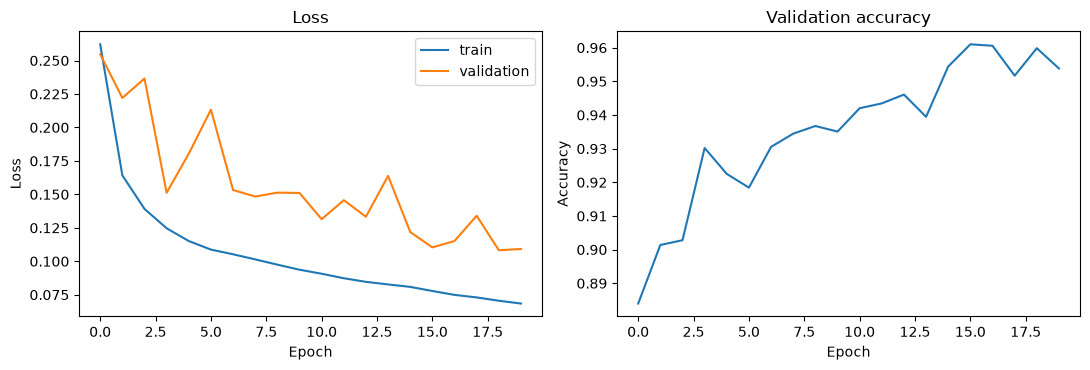

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="validation")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["val_acc"]); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].set_title("Validation accuracy")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/cnn_learning_curves.png", dpi=150)
plt.show()

## Step 6: Results on validation and test sets

In [7]:
val_prob  = predict_proba(model, X_val)
test_prob = predict_proba(model, X_test)
val_m,  val_pred  = evaluate(y_val,  val_prob,  "validation")
test_m, test_pred = evaluate(y_test, test_prob, "test")

keys = ["accuracy", "precision", "recall", "f1", "specificity", "fpr", "fnr", "roc_auc"]
print(f"{'Metric':14s} {'Validation':>12s} {'Test':>12s}")
for k in keys:
    print(f"{k:14s} {val_m[k]:12.4f} {test_m[k]:12.4f}")

sample = X_test[:10000]
t0 = time.time(); _ = predict_proba(model, sample); dt = time.time() - t0
print(f"\nInference time: {dt / len(sample) * 1000:.4f} ms/sample (batched, on {device})")

print("\nTest classification report:")
print(classification_report(y_test, test_pred, target_names=["Benign", "Attack"], digits=4))

Metric           Validation         Test
accuracy             0.9598       0.9606
precision            0.8086       0.8119
recall               0.9986       0.9982
f1                   0.8936       0.8955
specificity          0.9520       0.9530
fpr                  0.0480       0.0470
fnr                  0.0014       0.0018
roc_auc              0.9973       0.9974

Inference time: 0.0415 ms/sample (batched, on cpu)

Test classification report:
              precision    recall  f1-score   support

      Benign     0.9996    0.9530    0.9758    314259
      Attack     0.8119    0.9982    0.8955     63861

    accuracy                         0.9606    378120
   macro avg     0.9058    0.9756    0.9356    378120
weighted avg     0.9679    0.9606    0.9622    378120



## Step 7: Confusion matrix and ROC curve (test set)

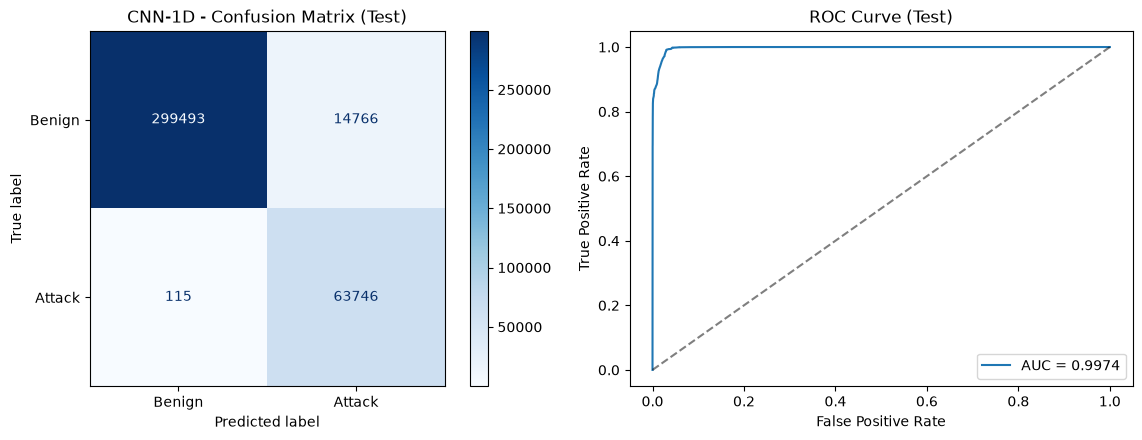

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["Benign", "Attack"]).plot(ax=ax[0], cmap="Blues", values_format="d")
ax[0].set_title("CNN-1D - Confusion Matrix (Test)")

fpr, tpr, _ = roc_curve(y_test, test_prob)
ax[1].plot(fpr, tpr, label=f"AUC = {test_m['roc_auc']:.4f}")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve (Test)"); ax[1].legend()

plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/cnn_clean_cm_roc.png", dpi=150)
plt.show()

## Step 8: Save results

In [9]:
with open(f"{RESULT_DIR}/cnn_clean_metrics.json", "w") as f:
    json.dump({"validation": val_m, "test": test_m, "train_time_s": train_time,
               "epochs_run": len(history["train_loss"]), "params": n_params,
               "settings": {"epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR, "train_sample": TRAIN_SAMPLE}}, f, indent=2)
with open(f"{RESULT_DIR}/cnn_history.json", "w") as f:
    json.dump(history, f)
print("Saved:", sorted(os.listdir(RESULT_DIR)))

Saved: ['cnn_clean_cm_roc.png', 'cnn_clean_metrics.json', 'cnn_history.json', 'cnn_learning_curves.png', 'decision_tree_clean_cm_roc.png', 'decision_tree_clean_metrics.json', 'decision_tree_feature_importance.png', 'kmeans_clean_cm_roc.png', 'kmeans_clean_metrics.json', 'logreg_clean_cm_roc.png', 'logreg_clean_metrics.json', 'lstm_clean_cm_roc.png', 'lstm_clean_metrics.json', 'lstm_history.json', 'lstm_learning_curves.png', 'svm_clean_cm_roc.png', 'svm_clean_metrics.json', 'xgboost_clean_cm_roc.png', 'xgboost_clean_metrics.json', 'xgboost_feature_importance.png']


## Step 9: Compare with all models trained so far

In [10]:
models = {"LogReg": "logreg_clean_metrics.json", "LinSVM": "svm_clean_metrics.json",
          "XGBoost": "xgboost_clean_metrics.json", "DecTree": "decision_tree_clean_metrics.json",
          "KMeans": "kmeans_clean_metrics.json", "LSTM": "lstm_clean_metrics.json",
          "CNN": "cnn_clean_metrics.json"}
res = {}
for name, fn_ in models.items():
    p = os.path.join(RESULT_DIR, fn_)
    if os.path.exists(p):
        res[name] = json.load(open(p))["test"]

print(f"{'Metric':14s}" + "".join(f"{n:>10s}" for n in res))
for k in keys:
    print(f"{k:14s}" + "".join(f"{res[n][k]:10.4f}" for n in res))

Metric            LogReg    LinSVM   XGBoost   DecTree    KMeans      LSTM       CNN
accuracy          0.7908    0.7955    0.9988    0.9983    0.6249    0.6663    0.9606
precision         0.4464    0.4521    0.9931    0.9914    0.3103    0.3333    0.8119
recall            0.9951    0.9938    0.9999    0.9987    0.9988    0.9757    0.9982
f1                0.6163    0.6215    0.9965    0.9950    0.4735    0.4969    0.8955
specificity       0.7493    0.7553    0.9986    0.9982    0.5490    0.6035    0.9530
fpr               0.2507    0.2447    0.0014    0.0018    0.4510    0.3965    0.0470
fnr               0.0049    0.0062    0.0001    0.0013    0.0012    0.0243    0.0018
roc_auc           0.9745    0.9759    1.0000    0.9986    0.9138    0.9017    0.9974


## Notes for the report and Phase 3
- The CNN is **differentiable**, so FGSM and PGD apply directly. Use `model(x)` on a flat `(B, F)` tensor with `requires_grad=True`. Unlike the LSTM, there is no cuDNN restriction on gradients in `eval()` mode.
- The 1D convolution slides over the feature vector, so it assumes neighbouring features are related. The order of CICIDS2017 features is arbitrary, so mention this as a limitation, as for the LSTM.
- Compare **FNR** across models: missed attacks are what adversarial evasion will try to increase.